# 07 · What does EEGNet respond to? Input × gradient attribution

A model can score well for the wrong reason (eye activity, noise). Input × gradient estimates how sensitive the output is to each channel and time point. Each fold's model is applied only to its own two held-out people. Requires the fold weights from notebook 03.

*Data: Gao et al. (2014), public Dryad release, doi:10.5061/dryad.2qc64. Own analysis; the plan (folds, training task, decision rule) was fixed before results.*

In [1]:
import os, json, numpy as np, matplotlib.pyplot as plt
# Point GAO_DIR at the "14 electrodes-30 subjects" folder of the Dryad release; GKT_WORK holds all derived files
os.environ.setdefault("GAO_DIR", "./data/14 electrodes-30 subjects/")
os.environ.setdefault("GKT_WORK", "./work/")
from gkt_utils import *
print("data:", GAO_DIR, "| work:", WORK)
import torch, torch.nn as nn

data: ./data/14 electrodes-30 subjects/ | work: ./work/


In [2]:
X, G, PID, SES, STIM = load_dataset()
PIDS = sorted(set(PID.tolist()))
print(X.shape, "epochs x channels x samples |", len(PIDS), "people |",
      {k: int((STIM == v).sum()) for k, v in STIM_CODE.items()})

(23388, 12, 128) epochs x channels x samples | 30 people | {'irrelevant': 15583, 'probe': 3890, 'target': 3915}


In [3]:
class EEGNet(nn.Module):
    """Lawhern et al. 2018 style: temporal conv -> depthwise spatial conv -> separable conv -> dense. 1,361 parameters."""
    def __init__(s, C=12, T=128, F1=8, D=2, F2=16, k=64, p=0.5):
        super().__init__()
        s.b1 = nn.Sequential(nn.Conv2d(1, F1, (1, k), padding=(0, k // 2), bias=False), nn.BatchNorm2d(F1),       # 8 temporal filters, 64 samples
                             nn.Conv2d(F1, F1 * D, (C, 1), groups=F1, bias=False), nn.BatchNorm2d(F1 * D),     # 2 spatial filters per temporal filter
                             nn.ELU(), nn.AvgPool2d((1, 4)), nn.Dropout(p))
        s.b2 = nn.Sequential(nn.Conv2d(F1 * D, F1 * D, (1, 16), padding=(0, 8), groups=F1 * D, bias=False),   # separable: depthwise in time
                             nn.Conv2d(F1 * D, F2, 1, bias=False),                                              #            + pointwise mix
                             nn.BatchNorm2d(F2), nn.ELU(), nn.AvgPool2d((1, 8)), nn.Dropout(p))
        with torch.no_grad(): n = s.b2(s.b1(torch.zeros(1, 1, C, T))).numel()
        s.fc = nn.Linear(n, 1)
    def forward(s, x): return s.fc(s.b2(s.b1(x.unsqueeze(1))).flatten(1)).squeeze(1)   # x: batch x 12 x 128

In [4]:
def rel(net, x):
    xt = torch.tensor(x, dtype=torch.float32, requires_grad=True); net(xt).sum().backward()
    return np.abs((xt.grad * xt).detach().numpy()).mean(0)            # 12 x 128
R = {}
for k, (pl, ph) in enumerate(PAIRS, 1):
    te = np.isin(PID, [pl, ph]); tr = (~te) & (STIM != 1) & ~np.isin(PID, list(inner_val(k)))
    mu = X[tr].mean((0, 2), keepdims=True); sd = X[tr].std((0, 2), keepdims=True)
    net = EEGNet(); net.load_state_dict(torch.load(P(f"weights/EEGNet_fold{k}.pt"))); net.eval()
    for p in (pl, ph):
        for c, nm in ((2, "target"), (1, "probe"), (0, "irrelevant")):
            m = (PID == p) & (STIM == c); R[(p, nm)] = rel(net, (X[m] - mu) / sd)
print(len(R), "person x condition maps")

90 person x condition maps


knowledgeable  probe      top channels ['Pz', 'Oz', 'P3'] | share in 300-800 ms 0.66
knowledgeable  irrelevant top channels ['Pz', 'Oz', 'P3'] | share in 300-800 ms 0.63
knowledgeable  target     top channels ['Pz', 'P3', 'Oz'] | share in 300-800 ms 0.66
control        probe      top channels ['Pz', 'Oz', 'P3'] | share in 300-800 ms 0.63
control        irrelevant top channels ['Pz', 'Oz', 'P3'] | share in 300-800 ms 0.63
control        target     top channels ['Pz', 'P3', 'Oz'] | share in 300-800 ms 0.65


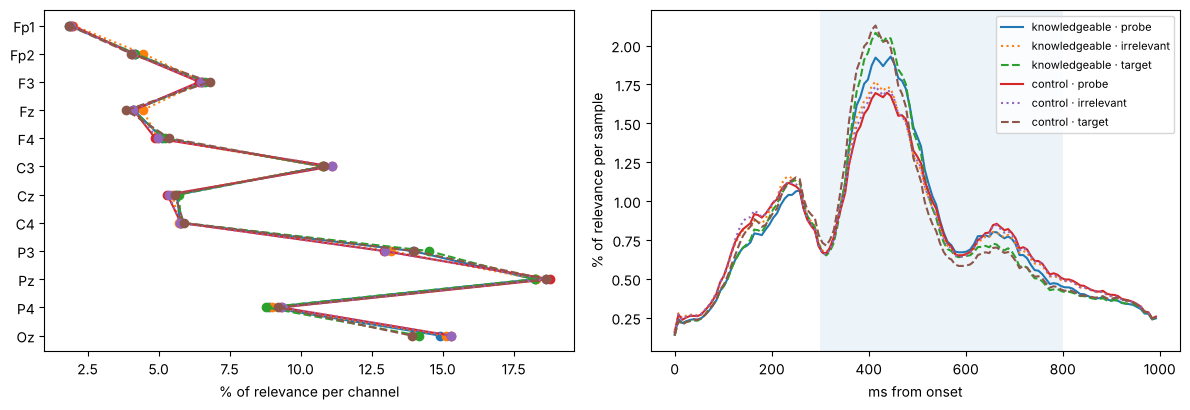

In [5]:
win = (TIME_MS >= 300) & (TIME_MS <= 800)
groups = {"knowledgeable": [100 + i for i in range(1, 16)], "control": list(range(1, 16))}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for gname, gl in groups.items():
    for nm, ls in (("probe", "-"), ("irrelevant", ":"), ("target", "--")):
        maps = np.stack([R[(p, nm)] / R[(p, nm)].sum() for p in gl])
        share = maps.sum(2).mean(0)[FRONT_TO_BACK] * 100
        ax[0].plot(share, range(12), ls, marker="o", label=f"{gname} · {nm}")
        ax[1].plot(TIME_MS, maps.sum(1).mean(0) * 100, ls, label=f"{gname} · {nm}")
        top = [EEG[i] for i in np.argsort(-maps.sum(2).mean(0))[:3]]
        print(f"{gname:14s} {nm:10s} top channels {top} | share in 300-800 ms {maps[:, :, win].sum((1, 2)).mean():.2f}")
ax[0].set_yticks(range(12)); ax[0].set_yticklabels([EEG[i] for i in FRONT_TO_BACK]); ax[0].invert_yaxis(); ax[0].set_xlabel("% of relevance per channel")
ax[1].axvspan(300, 800, alpha=.08); ax[1].set_xlabel("ms from onset"); ax[1].set_ylabel("% of relevance per sample"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** Relevance concentrates on Pz, Oz and P3 inside the P300 window for target, probe and irrelevant epochs in both groups; Fp1 + Fp2 carry about 6 %. Attribution shows model sensitivity under this method — not a cortical source, a unique mechanism or causal dependence. Eye channels were neither used nor corrected, so ocular influence is reduced, not excluded.